In [1]:
import sys
import utils as utils
from importlib import reload
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
reload(utils)

<module 'utils' from '/Users/leandrosb/Documents/GitHub/amm-make-take-fee/utils.py'>

In [2]:
%load_ext autoreload
%autoreload 2
np.random.seed(100)

In [3]:
import matplotlib.pylab as pylab
params = {'legend.fontsize': 'x-large',
          'figure.figsize': (8, 5),
         'axes.labelsize': 'x-large',
         'axes.titlesize':'x-large',
         'xtick.labelsize':'x-large',
         'ytick.labelsize':'x-large'}
pylab.rcParams.update(params)
%config InlineBackend.figure_format = "retina"

import matplotlib
plt.rc('text', usetex=True)
plt.rc('text.latex', preamble=r'\usepackage{amsmath,amsfonts}')

In [33]:
params_env = {'sigma': 1., 'S0': 100, 'Z0': 100., 'Y0': 1_000., 
              'eta': 1., 'xi': .5, 'T': 1., 'a1': 5., 'a2': .1, 'a3': 100., 'Nt': 10_000,
              'fee': .1, 'feeV': .1, 'C': .1, 'gamma': 1e-2, 'zeta': 1e-2, 'tempLP': 1e-2}

In [34]:
env = utils.environment(**params_env)

In [35]:
nsims = 100
strag = '1'

#S, Y, Z, X, nu, wealth, perf, rew = env.simulate_venue(nsims=nsims, strag=strag)
S, Y, Z, X, nu, wealth, perf, rew, A_a_hist, A_b_hist, A_W_hist, A_B_hist = env.simulate_venue(nsims=nsims, strag=strag, verbose = True)

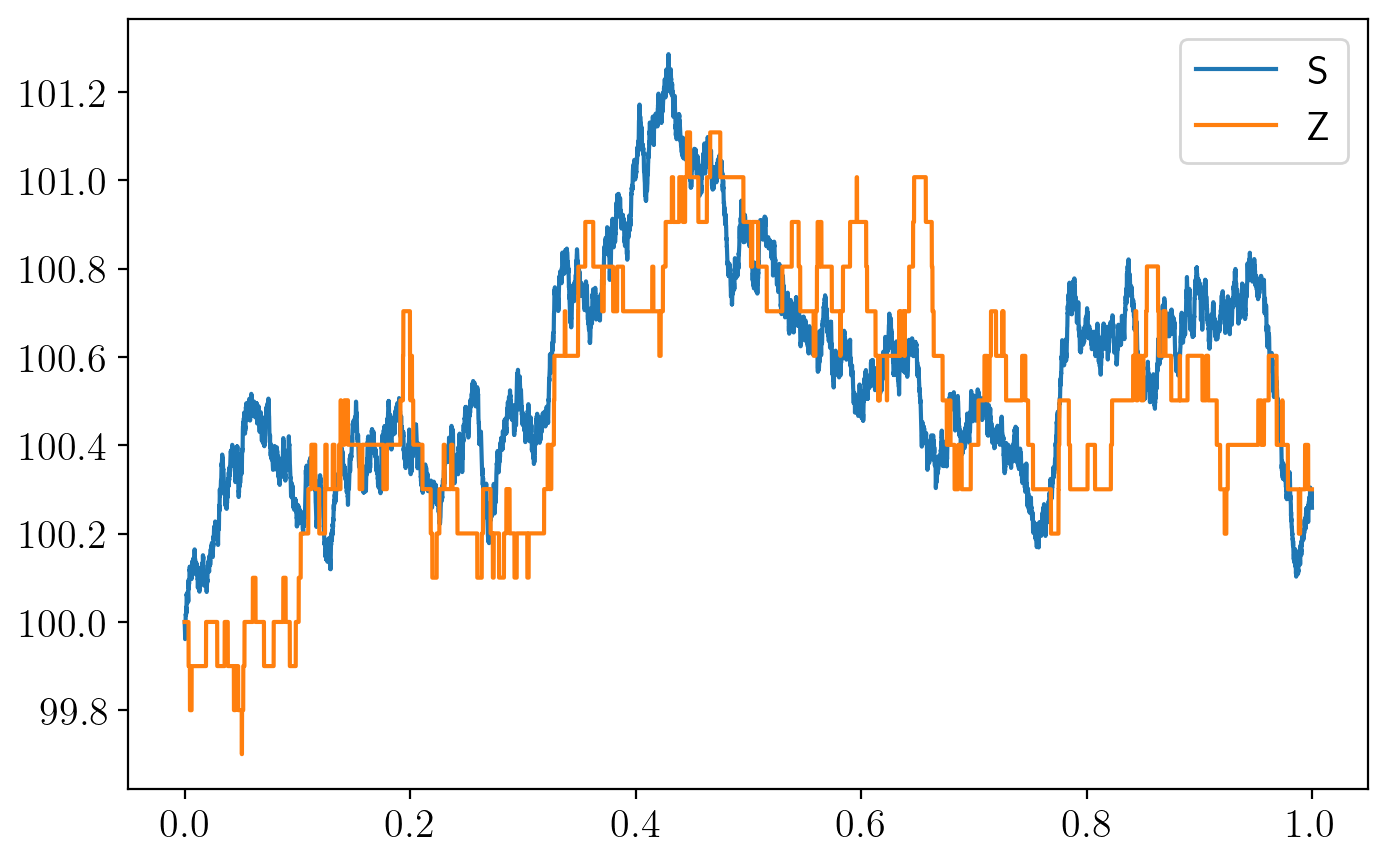

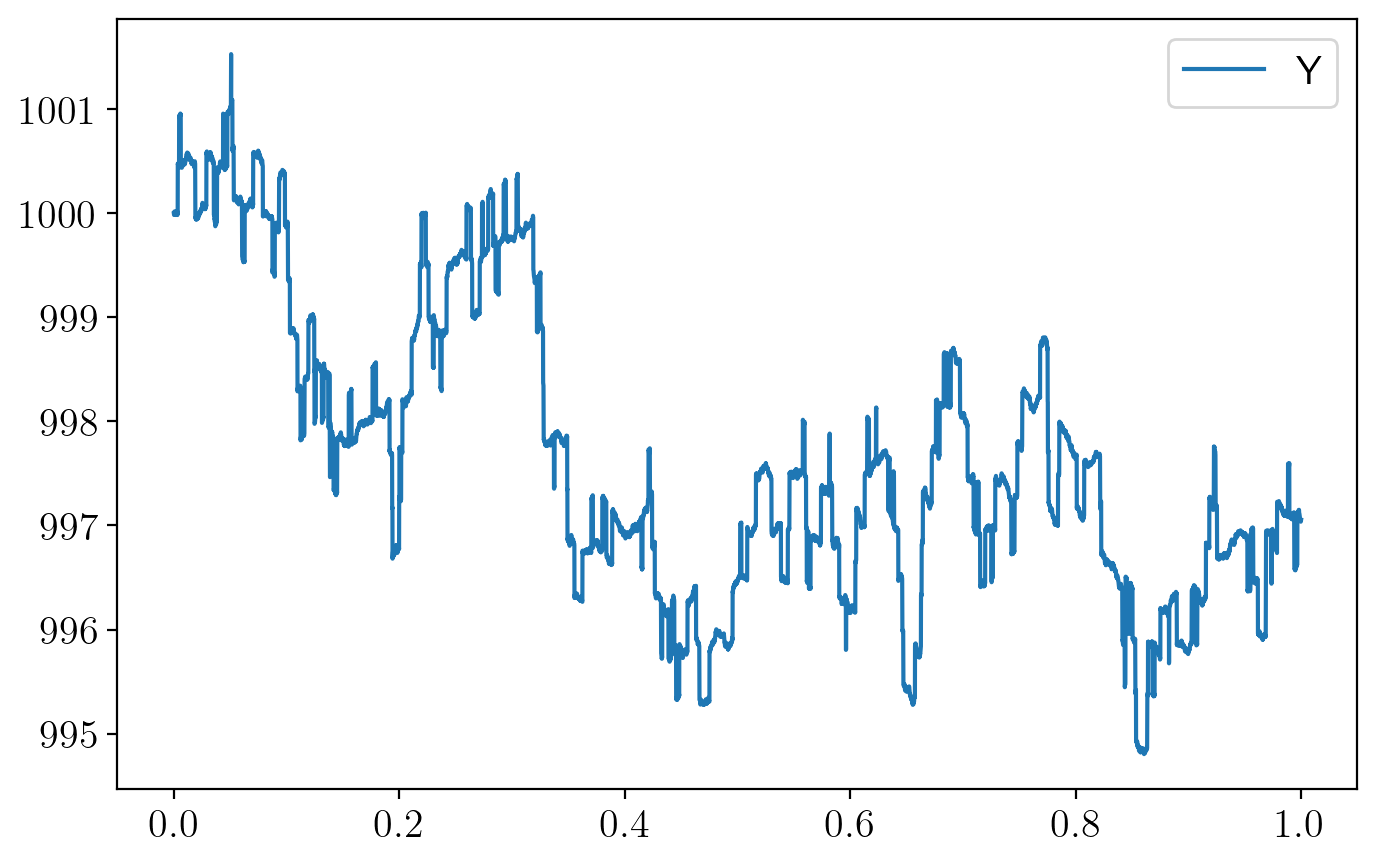

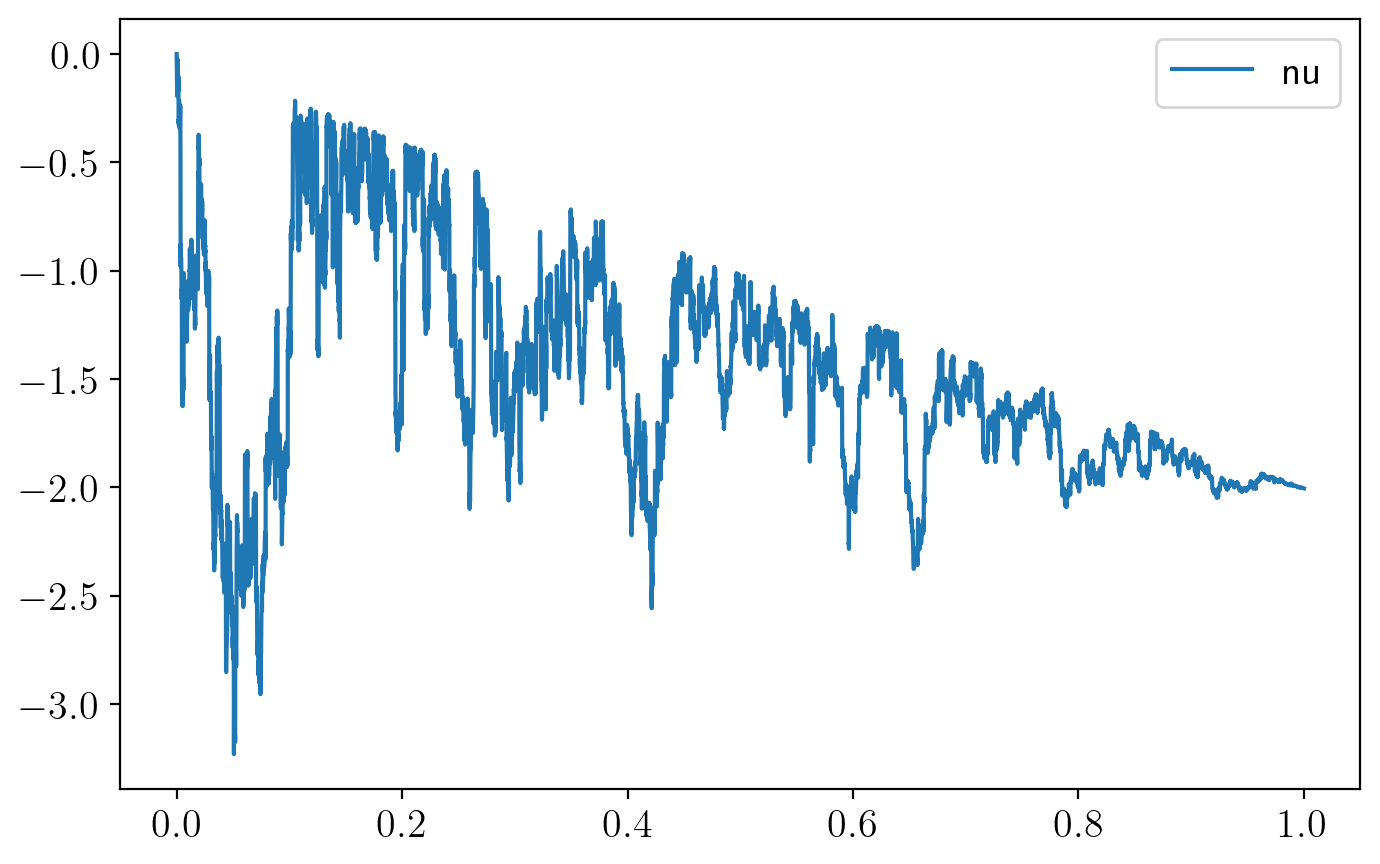

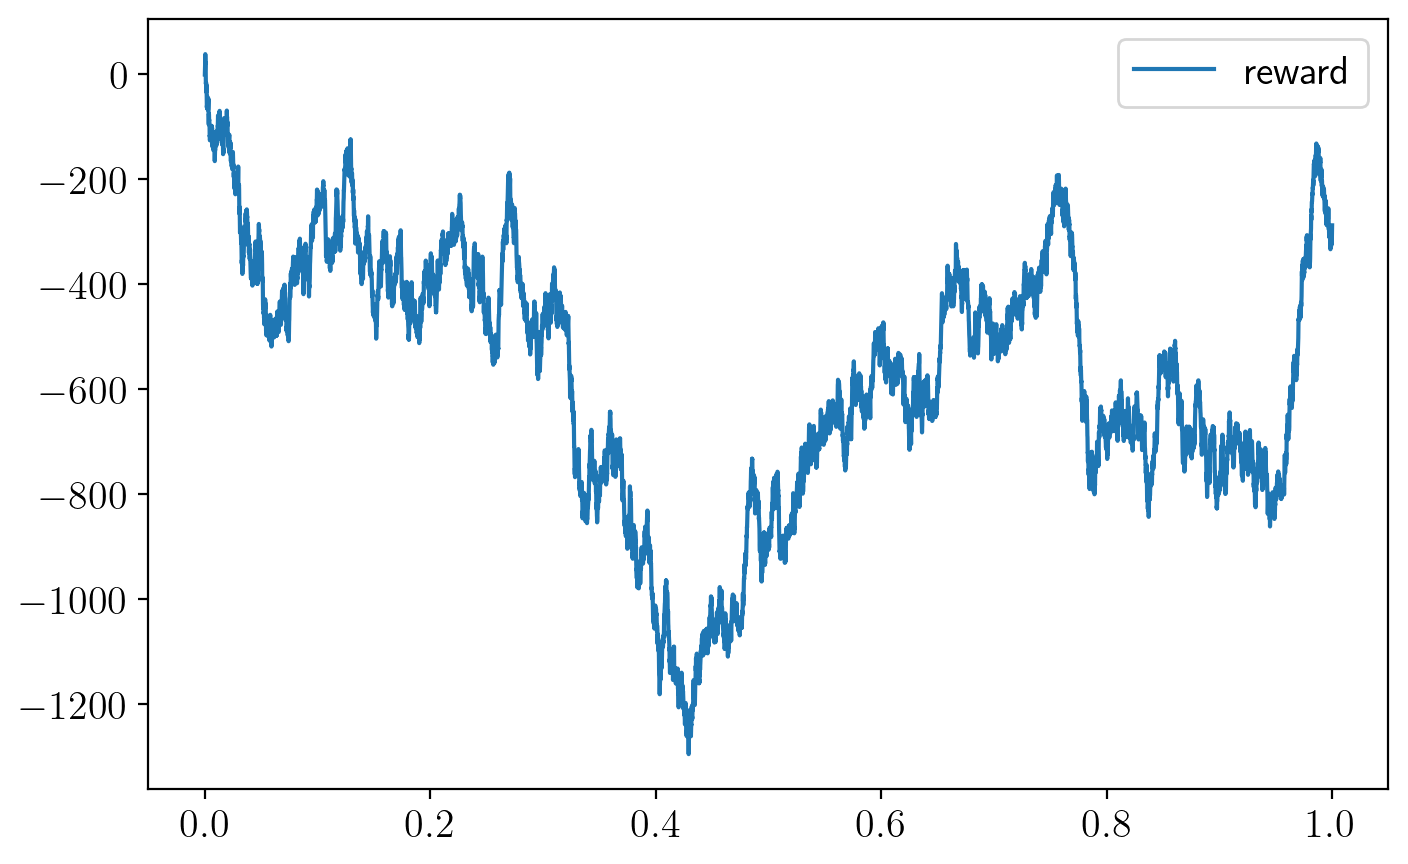

In [36]:
num_sim = 59

plt.plot(env.timesteps, S[:,num_sim], label='S')
plt.plot(env.timesteps, Z[:,num_sim], label='Z')
plt.legend()
plt.show()

plt.plot(env.timesteps, Y[:,num_sim], label='Y')
plt.legend()
plt.show()

#plt.plot(env.timesteps, Z[:,num_sim], label='Z')
#plt.legend()
#plt.show()

#plt.plot(env.timesteps, X[:,num_sim], label='X')
#plt.legend()
#plt.show()

plt.plot(env.timesteps, nu[:,num_sim], label='nu')
plt.legend()
plt.show()


plt.plot(env.timesteps, rew[:,num_sim], label='reward')
plt.legend()
plt.show()



/Applications/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


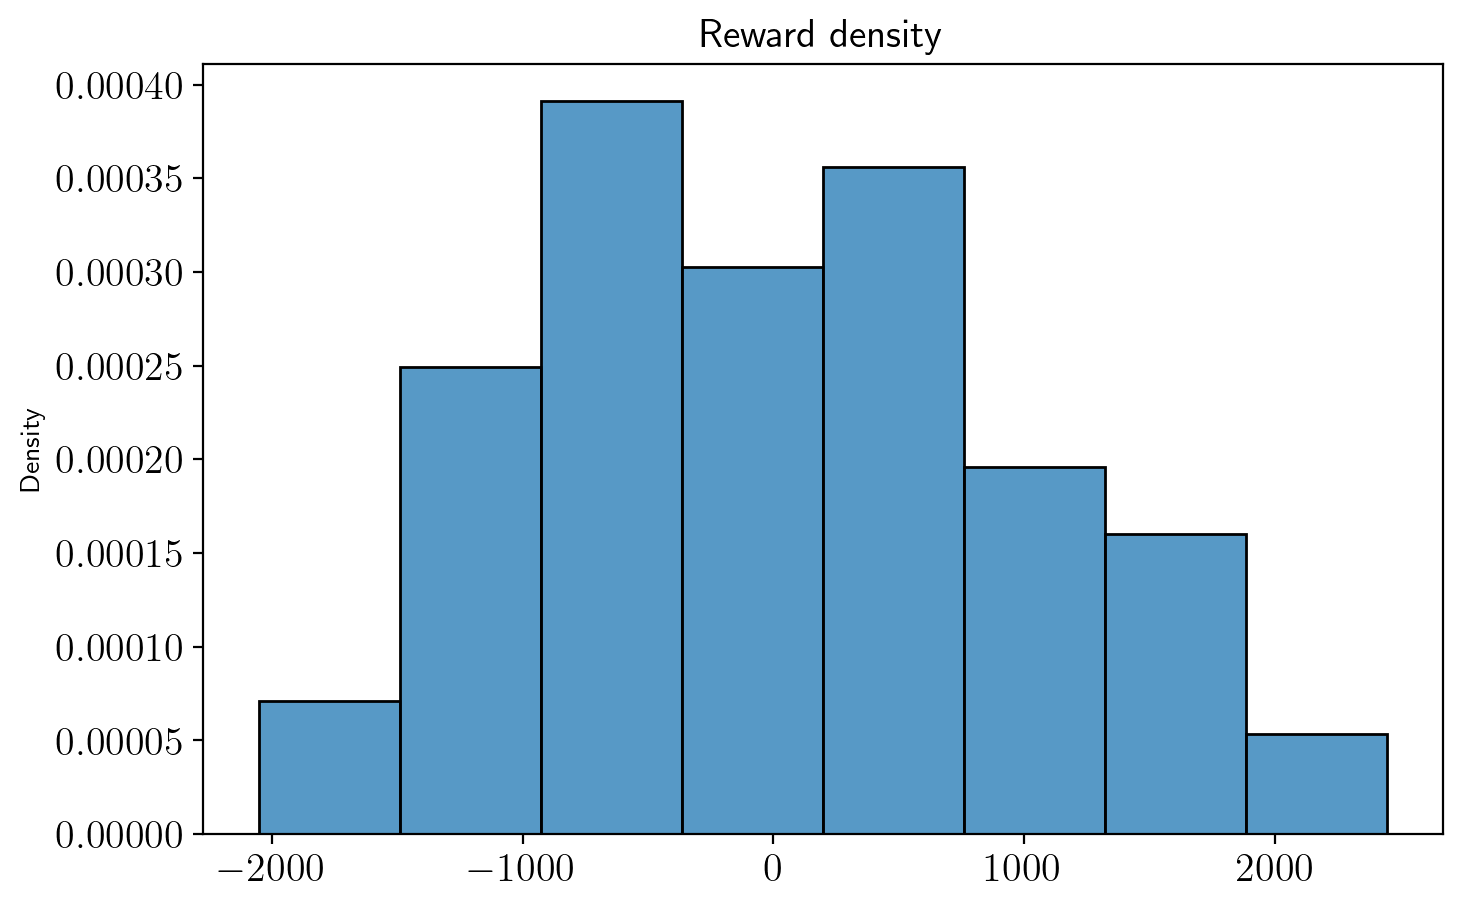

/Applications/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


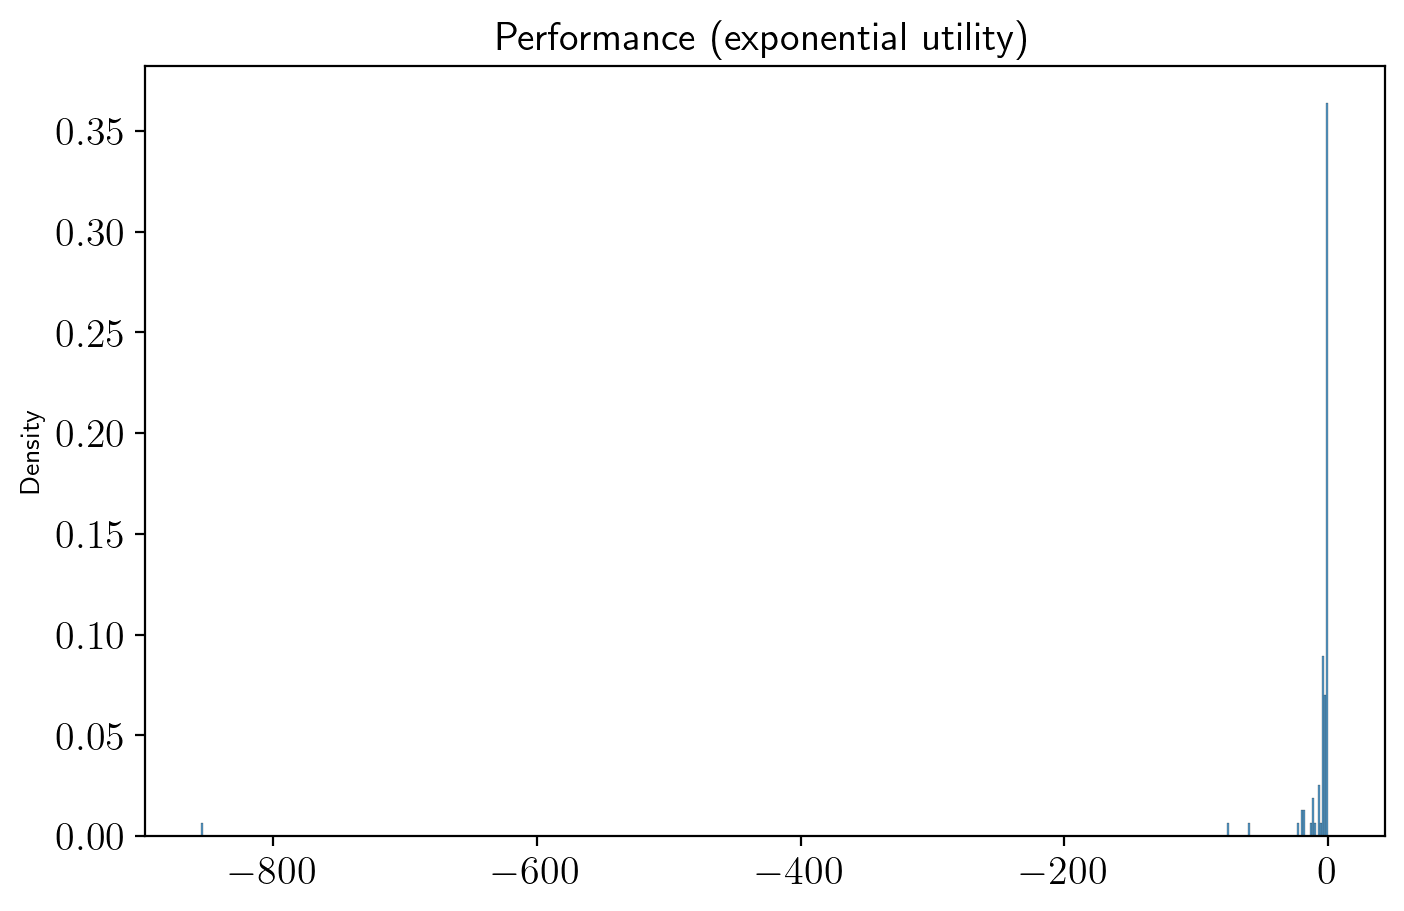

Expected performance (exponential utility, strag:1): -12.863


In [37]:
sns.histplot(rew[-1,:], stat='density')
plt.title("Reward density")
plt.show()

sns.histplot(perf[0,:], stat='density')
plt.title("Performance (exponential utility)")
plt.show()

print(f'Expected performance (exponential utility, strag:{strag}): {perf[0,:].mean():1.3f}')

# LP does not trade

In [68]:
nsims = 2000
strag = '0'

S, Y, Z, X, nu, wealth, perf, rew = env.simulate_venue(nsims=nsims, strag=strag)

/Applications/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


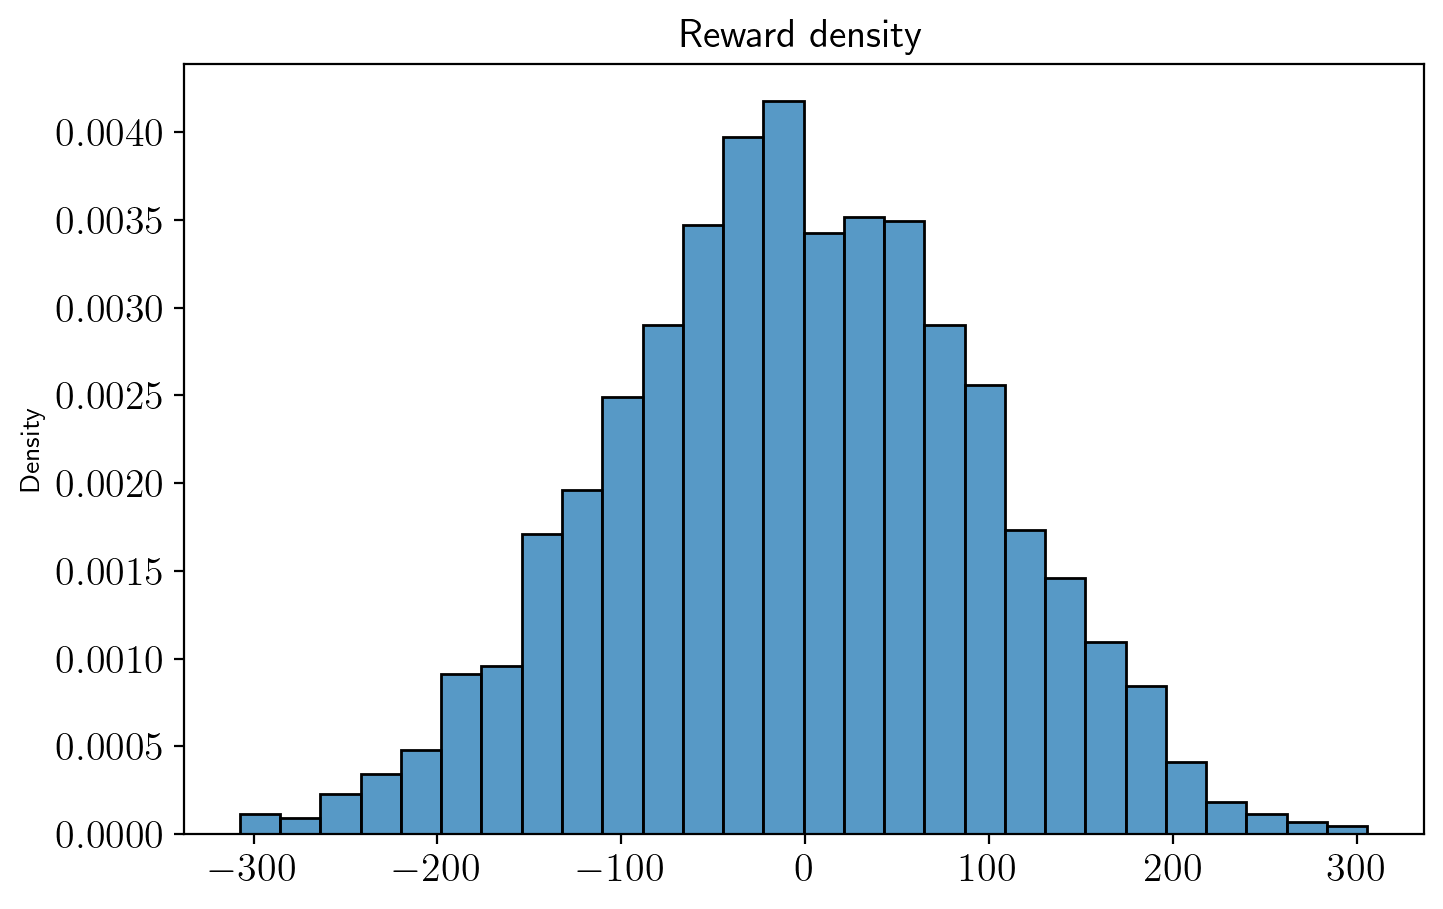

/Applications/anaconda3/lib/python3.10/site-packages/seaborn/_oldcore.py:1119: FutureWarning: use_inf_as_na option is deprecated and will be removed in a future version. Convert inf values to NaN before operating instead.
  with pd.option_context('mode.use_inf_as_na', True):


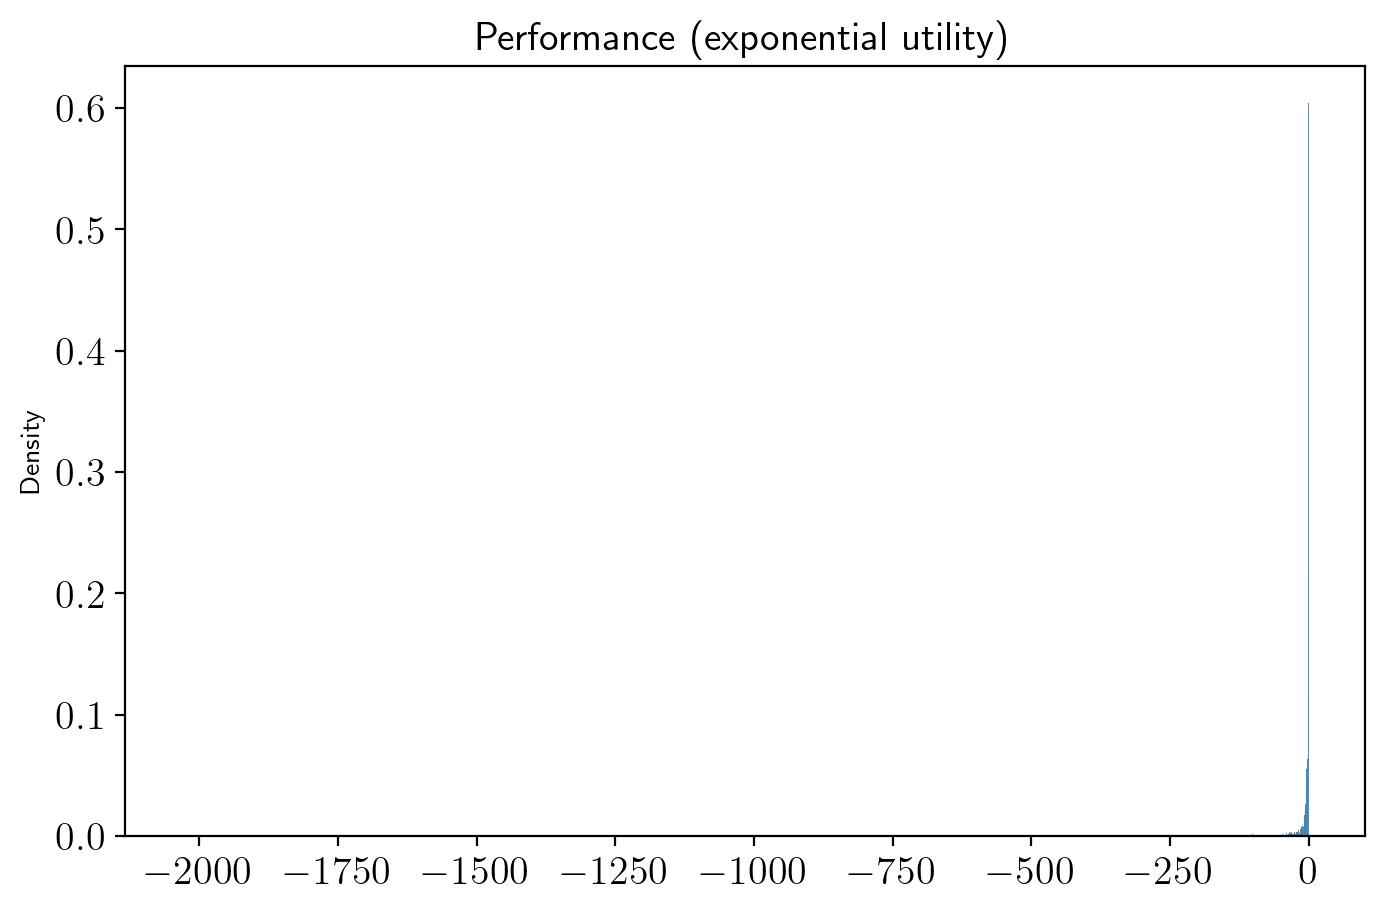

Expected performance (exponential utility, strag:0): -8.451


In [69]:
sns.histplot(rew[-1,:], stat='density')
plt.title("Reward density")
plt.show()

sns.histplot(perf[0,:], stat='density')
plt.title("Performance (exponential utility)")
plt.show()

print(f'Expected performance (exponential utility, strag:{strag}): {perf[0,:].mean():1.3f}')